<a href="https://colab.research.google.com/github/srinivasrom/MyStore/blob/master/CNN_waste_segregation_Srinivas_Rompala.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Waste Material Segregation for Improving Waste Management**

## **Objective**

The objective of this project is to implement an effective waste material segregation system using convolutional neural networks (CNNs) that categorises waste into distinct groups. This process enhances recycling efficiency, minimises environmental pollution, and promotes sustainable waste management practices.

The key goals are:

* Accurately classify waste materials into categories like cardboard, glass, paper, and plastic.
* Improve waste segregation efficiency to support recycling and reduce landfill waste.
* Understand the properties of different waste materials to optimise sorting methods for sustainability.

## **Data Understanding**

The Dataset consists of images of some common waste materials.

1. Food Waste
2. Metal
3. Paper
4. Plastic
5. Other
6. Cardboard
7. Glass


**Data Description**

* The dataset consists of multiple folders, each representing a specific class, such as `Cardboard`, `Food_Waste`, and `Metal`.
* Within each folder, there are images of objects that belong to that category.
* However, these items are not further subcategorised. <br> For instance, the `Food_Waste` folder may contain images of items like coffee grounds, teabags, and fruit peels, without explicitly stating that they are actually coffee grounds or teabags.

## **1. Load the data**

Load and unzip the dataset zip file.

**Import Necessary Libraries**

In [ ]:
# Recommended versions:

# numpy version: 1.26.4
# pandas version: 2.2.2
# seaborn version: 0.13.2
# matplotlib version: 3.10.0
# PIL version: 11.1.0
# tensorflow version: 2.18.0
# keras version: 3.8.0
# sklearn version: 1.6.1

Load the dataset.

In [28]:
import warnings

!pip install -U "numpy>=2.1"
import numpy as np

#!pip install pandas==2.2.2
import pandas as pd
#!pip install matplotlib==3.10.0
import matplotlib as plt
#!pip install seaborn==0.13.2
import seaborn as sns
import os
import zipfile
# Image processing
from PIL import Image
# TensorFlow / Keras
import tensorflow as tf


# Model evaluation
from sklearn.metrics import classification_report, confusion_matrix

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

import importlib.metadata as md

print(md.version("jax"))
print(md.version("jaxlib"))

0.11.1
0.11.1


In [11]:
# Load and unzip the dataset file Dataset_Waste_Segregation
import zipfile
import os

zip_file = "/content/Wastage_Segregation.zip"
extract_path = "/content/Data_Segregation"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted to:", extract_path)




Extracted to: /content/Data_Segregation


## **2. Data Preparation** <font color=red> [25 marks] </font><br>


### **2.1 Load and Preprocess Images** <font color=red> [8 marks] </font><br>

Let us create a function to load the images first. We can then directly use this function while loading images of the different categories to load and crop them in a single step.

#### **2.1.1** <font color=red> [3 marks] </font><br>
Create a function to load the images.

In [1]:
# Create a function to load the raw images
import os
import numpy as np
from PIL import Image
import os
import numpy as np
from PIL import Image

def load_raw_images(data_path, max_images_per_folder=50):
    images = []
    labels = []

    # Find all folders/classes
    class_names = sorted([
        folder for folder in os.listdir(data_path)
        if os.path.isdir(os.path.join(data_path, folder))
    ])

    # Create label mapping
    label_map = {
        class_name: i
        for i, class_name in enumerate(class_names)
    }

    print("Classes:", class_names)
    print("Label mapping:", label_map)

    # Load limited number of images from each folder
    for class_name in class_names:

        class_path = os.path.join(data_path, class_name)

        # Get only PNG files
        image_files = [
            file for file in os.listdir(class_path)
            if file.lower().endswith(".png")
        ]

        # Take only the first N images
        image_files = image_files[:max_images_per_folder]

        print(f"{class_name}: loading {len(image_files)} images")

        for filename in image_files:

            image_path = os.path.join(class_path, filename)

            try:
                image = Image.open(image_path).convert("RGB")
                image = np.array(image)

                images.append(image)
                labels.append(label_map[class_name])

            except Exception as e:
                print(f"Error loading {image_path}: {e}")

    return images, np.array(labels), class_names

print(os.path.exists("/content/Data_Segregation/data"))
print(os.listdir("/content/Data_Segregation/data"))

True
['Metal', 'Glass', 'Cardboard', 'Other', 'Food_Waste', 'Plastic', 'Paper']


#### **2.1.2** <font color=red> [5 marks] </font><br>
Load images and labels.

Load the images from the dataset directory. Labels of images are present in the subdirectories.

Verify if the images and labels are loaded correctly.

In [13]:
# Get the images and their labels
data_path = "/content/Data_Segregation/data"

images, labels, class_names = load_raw_images(
    data_path,
    max_images_per_folder=50
)

print("Total images:", len(images))
print("Total labels:", len(labels))
print("Classes:", class_names)

print("Shape of X:", X.shape)
print("Shape of labels:", labels.shape)


# Perform any operations, if needed, on the images and labels to get them into the desired format.
IMG_SIZE = (224, 224)

resized_images = []

for image in images:
    # Convert NumPy array back to PIL image
    img = Image.fromarray(image.astype('uint8'))

    # Resize to 224 x 224
    img = img.resize(IMG_SIZE)

    # Convert back to NumPy array
    img = np.array(img)

    resized_images.append(img)

# Convert list to NumPy array
X = np.array(resized_images)

print("Original number of images:", len(images))
print("Resized images shape:", X.shape)
print("Data type:", X.dtype)


Classes: ['Cardboard', 'Food_Waste', 'Glass', 'Metal', 'Other', 'Paper', 'Plastic']
Label mapping: {'Cardboard': 0, 'Food_Waste': 1, 'Glass': 2, 'Metal': 3, 'Other': 4, 'Paper': 5, 'Plastic': 6}
Cardboard: loading 50 images
Food_Waste: loading 50 images
Glass: loading 50 images
Metal: loading 50 images
Other: loading 50 images
Paper: loading 50 images
Plastic: loading 50 images
Total images: 350
Total labels: 350
Classes: ['Cardboard', 'Food_Waste', 'Glass', 'Metal', 'Other', 'Paper', 'Plastic']
Shape of X: (350, 224, 224, 3)
Shape of labels: (350,)
Original number of images: 350
Resized images shape: (350, 224, 224, 3)
Data type: uint8


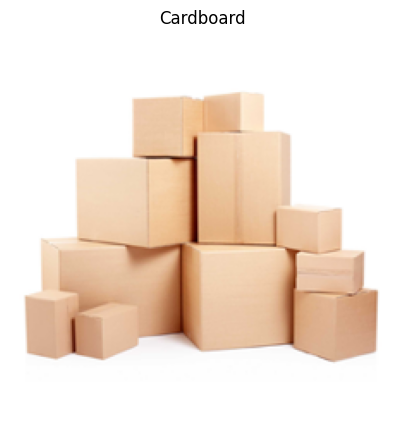

Shape of X: (350, 224, 224, 3)
Shape of labels: (350,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [14]:
plt.figure(figsize=(5, 5))

plt.imshow(X[0])
plt.title(class_names[labels[0]])
plt.axis("off")

plt.show()
print("Shape of X:", X.shape)
print("Shape of labels:", labels.shape)

X = X.astype("float32") / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Perform any operations, if needed, on the images and labels to get them into the desired format.

### **2.2 Data Visualisation** <font color=red> [9 marks] </font><br>

#### **2.2.1** <font color=red> [3 marks] </font><br>
Create a bar plot to display the class distribution

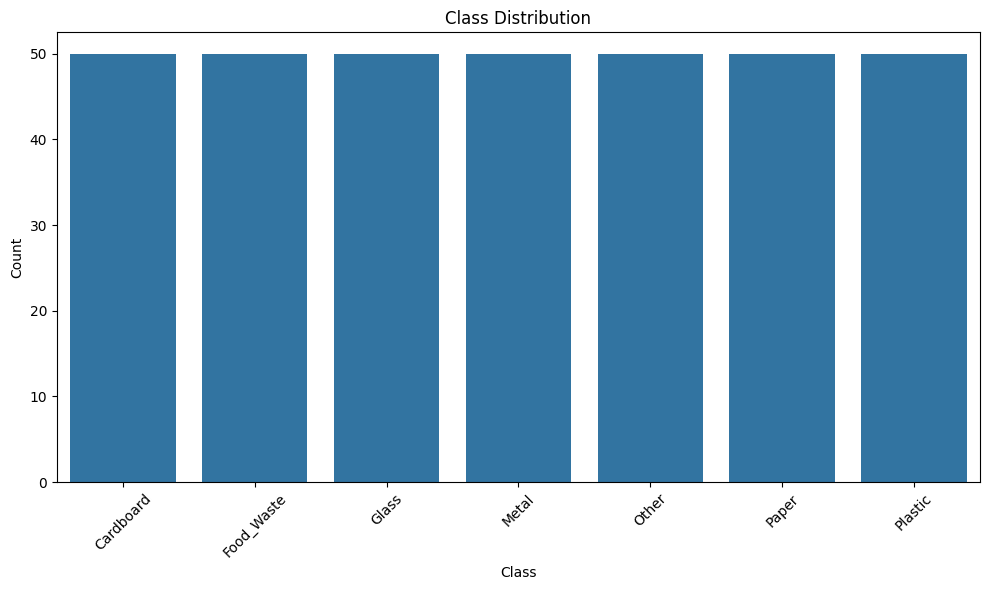

In [20]:
# Visualise Data Distribution
#Create a bar plot to display the class distribution
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(10, 6))



sns.countplot(
    x=labels,
    order=range(len(class_names))
)

plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Class Distribution')

# Replace numeric labels with class names
plt.xticks(
    ticks=range(len(class_names)),
    labels=class_names,
    rotation=45
)

plt.tight_layout()
plt.show()



#### **2.2.2** <font color=red> [3 marks] </font><br>
Visualise some sample images

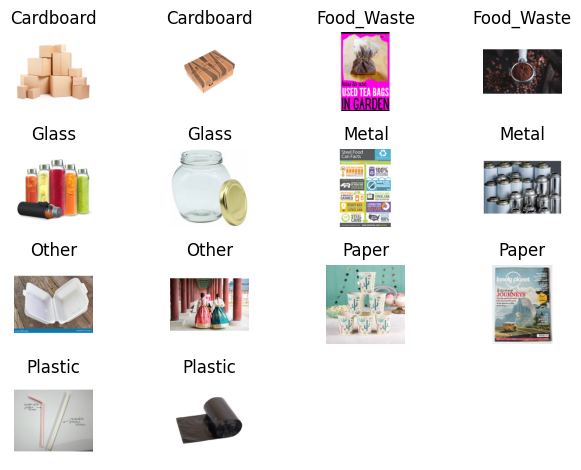

In [17]:
# Visualise Sample Images (across different labels)
import matplotlib.pyplot as plt
import numpy as np

for class_id, class_name in enumerate(class_names):

    # Find images belonging to this class
    indices = [i for i, label in enumerate(labels) if label == class_id]

    # Show first 2 images from each class
    for j, idx in enumerate(indices[:2]):

        position = class_id * 2 + j + 1

        plt.subplot(4, 4, position)
        plt.imshow(images[idx])
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


#### **2.2.3** <font color=red> [3 marks] </font><br>
Based on the smallest and largest image dimensions, resize the images.

In [21]:
# Find the smallest and largest image dimensions from the data set

IMG_SIZE = (224, 224)

resized_images = []

for image in images:
    # Convert NumPy array back to PIL image
    img = Image.fromarray(image.astype('uint8'))

    # Resize to 224 x 224
    img = img.resize(IMG_SIZE)

    # Convert back to NumPy array
    img = np.array(img)

    resized_images.append(img)

# Convert list to NumPy array
X = np.array(resized_images)

print("Original number of images:", len(images))
print("Resized images shape:", X.shape)
print("Data type:", X.dtype)

Original number of images: 350
Resized images shape: (350, 224, 224, 3)
Data type: uint8


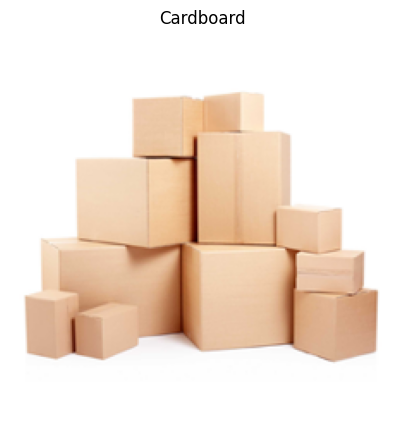

Shape of X: (350, 224, 224, 3)
Shape of labels: (350,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [24]:
# Resize the image dimensions
plt.figure(figsize=(5, 5))

plt.imshow(X[0])
plt.title(class_names[labels[0]])
plt.axis("off")

plt.show()

print("Shape of X:", X.shape)
print("Shape of labels:", labels.shape)

X = X.astype("float32") / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


### **2.3 Encoding the classes** <font color=red> [3 marks] </font><br>

There are seven classes present in the data.

We have extracted the images and their labels, and visualised their distribution. Now, we need to perform encoding on the labels. Encode the labels suitably.

####**2.3.1** <font color=red> [3 marks] </font><br>
Encode the target class labels.

In [27]:
# Encode the labels suitably
from tensorflow.keras.utils import to_categorical
y = to_categorical(labels, num_classes=len(class_names))

print("Original labels shape:", labels.shape)
print("Encoded labels shape:", y.shape)


print("Original label:", labels[0])
print("Encoded label:", y[0])

Original labels shape: (350,)
Encoded labels shape: (350, 7)
Original label: 0
Encoded label: [1. 0. 0. 0. 0. 0. 0.]


### **2.4 Data Splitting** <font color=red> [5 marks] </font><br>

#### **2.4.1** <font color=red> [5 marks] </font><br>
Split the dataset into training and validation sets

In [32]:
# Assign specified parts of the dataset to train and validation sets
from sklearn.model_selection import train_test_split


X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)


Training data: (280, 224, 224, 3)
Validation data: (70, 224, 224, 3)
Training labels: (280, 7)
Validation labels: (70, 7)


## **3. Model Building and Evaluation** <font color=red> [20 marks] </font><br>

### **3.1 Model building and training** <font color=red> [15 marks] </font><br>

#### **3.1.1** <font color=red> [10 marks] </font><br>
Build and compile the model. Use 3 convolutional layers. Add suitable normalisation, dropout, and fully connected layers to the model.

Test out different configurations and report the results in conclusions.

In [33]:
# Build and compile the model

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([

    # Input + Convolutional Layer 1
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(224, 224, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Convolutional Layer 2
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Convolutional Layer 3
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Fully Connected Layers
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    # Output layer - 7 classes
    Dense(7, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,759 (42.61 MB)

 Trainable params: 11,170,311 (42.61 MB)

 Non-trainable params: 448 (1.75 KB)

#### **3.1.2** <font color=red> [5 marks] </font><br>
Train the model.

Use appropriate metrics and callbacks as needed.

In [43]:
# Training
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50, # increasing further to train the model in good shape from 20 to 50
    batch_size=32
)

Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 652ms/step - accuracy: 0.5429 - loss: 1.6248 - val_accuracy: 0.1286 - val_loss: 25.4121
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - accuracy: 0.5821 - loss: 2.5926 - val_accuracy: 0.1429 - val_loss: 22.6801
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.5643 - loss: 2.1254 - val_accuracy: 0.1429 - val_loss: 25.7244
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.5286 - loss: 2.5098 - val_accuracy: 0.1000 - val_loss: 20.2908
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.5286 - loss: 2.2634 - val_accuracy: 0.1429 - val_loss: 25.2868
Epoch 6/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.5714 - loss: 2.4771 - val_accuracy: 0.1429 - val_loss: 25.2993
Epoch 7/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.5929 - loss: 1.6690 - val_accuracy: 0.1286 - val_loss: 21.7597
Epoch 8/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.5964 - loss: 1.5094 - val_accuracy: 0.1429 - val_loss

### **3.2 Model Testing and Evaluation** <font color=red> [5 marks] </font><br>

#### **3.2.1** <font color=red> [5 marks] </font><br>
Evaluate the model on test dataset. Derive appropriate metrics.

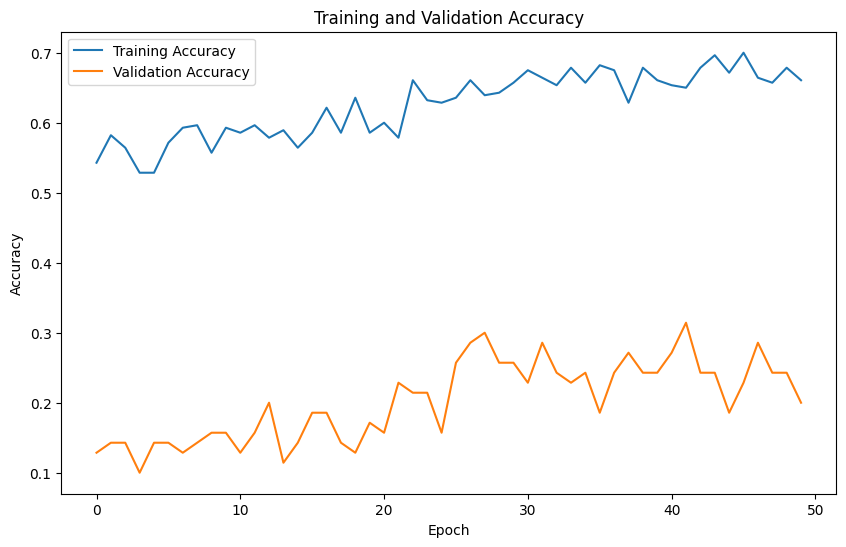

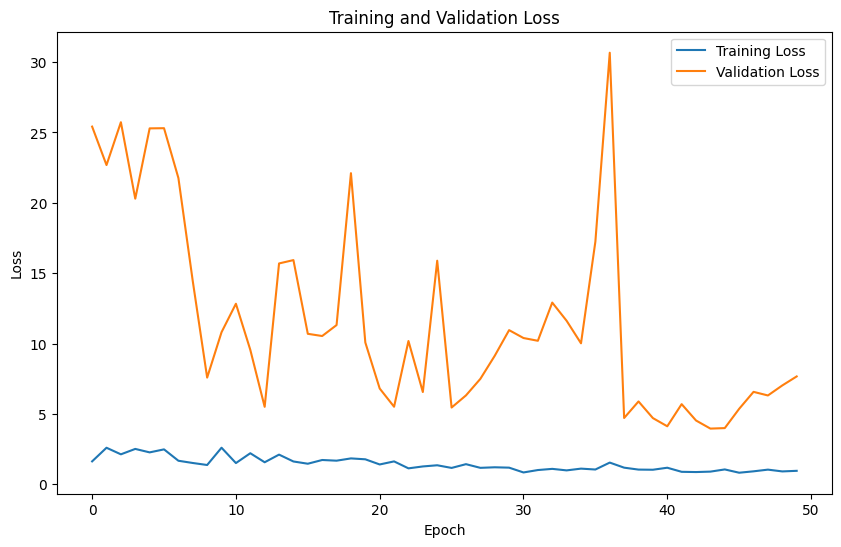

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.2000 - loss: 7.6600
Validation Loss: 7.660046577453613
Validation Accuracy: 0.20000000298023224


In [44]:
# Evaluate on the test set; display suitable metrics
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.show()
plt.figure(figsize=(10, 6))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.show()

val_loss, val_accuracy = model.evaluate(X_val, y_val)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

Final Training Accuracy: 0.5607143044471741
Final Validation Accuracy: 0.17142857611179352


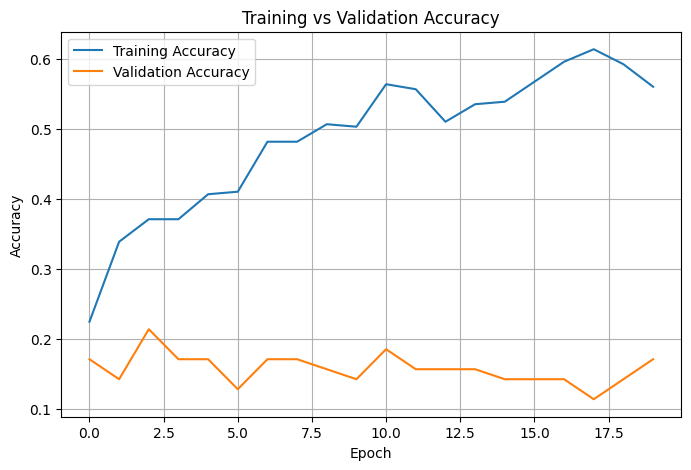

Training accuracy:
[0.22499999403953552, 0.3392857015132904, 0.37142857909202576, 0.37142857909202576, 0.40714284777641296, 0.4107142984867096, 0.4821428656578064, 0.4821428656578064, 0.5071428418159485, 0.5035714507102966, 0.5642856955528259, 0.5571428537368774, 0.5107142925262451, 0.5357142686843872, 0.5392857193946838, 0.5678571462631226, 0.5964285731315613, 0.6142857074737549, 0.5928571224212646, 0.5607143044471741]

Validation accuracy:
[0.17142857611179352, 0.1428571492433548, 0.2142857164144516, 0.17142857611179352, 0.17142857611179352, 0.12857143580913544, 0.17142857611179352, 0.17142857611179352, 0.15714286267757416, 0.1428571492433548, 0.18571428954601288, 0.15714286267757416, 0.15714286267757416, 0.15714286267757416, 0.1428571492433548, 0.1428571492433548, 0.1428571492433548, 0.11428571492433548, 0.1428571492433548, 0.17142857611179352]

Training loss:
[20.212560653686523, 10.980997085571289, 8.242602348327637, 5.637721061706543, 3.4345104694366455, 2.553689956665039, 1.7996

In [42]:
print("Final Training Accuracy:", history.history['accuracy'][-1])
print("Final Validation Accuracy:", history.history['val_accuracy'][-1])

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

print("Training accuracy:")
print(history.history['accuracy'])

print("\nValidation accuracy:")
print(history.history['val_accuracy'])

print("\nTraining loss:")
print(history.history['loss'])

print("\nValidation loss:")
print(history.history['val_loss'])

## **4. Data Augmentation** <font color=red> [optional] </font><br>

#### **4.1 Create a Data Augmentation Pipeline**

##### **4.1.1**
Define augmentation steps for the datasets.

In [45]:
# Define augmentation steps to augment images

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    RandomFlip,
    RandomRotation,
    RandomZoom
)

# Data augmentation
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

# Model 2
model2 = Sequential([
    data_augmentation,

    Conv2D(32, (3, 3), activation='relu',
           input_shape=(224, 224, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(7, activation='softmax')
])

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Augment and resample the images.
In case of class imbalance, you can also perform adequate undersampling on the majority class and augment those images to ensure consistency in the input datasets for both classes.

Augment the images.

In [54]:
# Create a function to augment the images


import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def augment_images(X, y, augmentations_per_image=3):

    # Define augmentation techniques
    datagen = ImageDataGenerator(
        rotation_range=20,
        width_shift_range=0.1,
        height_shift_range=0.1,
        zoom_range=0.1,
        horizontal_flip=True,
        fill_mode='nearest'
    )

    augmented_images = []
    augmented_labels = []

    # Generate augmented images
    for i in range(len(X)):

        image = X[i]
        label = y[i]

        # Add batch dimension
        image = np.expand_dims(image, axis=0)

        # Generate augmented versions
        image_generator = datagen.flow(
            image,
            batch_size=1,
            shuffle=False
        )

        for _ in range(augmentations_per_image):
            augmented_image = next(image_generator)[0]

            augmented_images.append(augmented_image)
            augmented_labels.append(label)

    # Convert to NumPy arrays
    augmented_images = np.array(augmented_images)
    augmented_labels = np.array(augmented_labels)

    # Combine original and augmented images
    X_augmented = np.concatenate(
        [X, augmented_images],
        axis=0
    )

    y_augmented = np.concatenate(
        [y, augmented_labels],
        axis=0
    )

    return X_augmented, y_augmented



In [58]:
X_train_augmented, y_train_augmented = augment_images(
    X_train,
    y_train,
    augmentations_per_image=3
)
print("Original training images:", X_train.shape)
print("Augmented training images:", X_train_augmented.shape)

print("Original training labels:", y_train.shape)
print("Augmented training labels:", y_train_augmented.shape)





Original training images: (280, 224, 224, 3)
Augmented training images: (1120, 224, 224, 3)
Original training labels: (280, 7)
Augmented training labels: (1120, 7)


In [59]:
# Create the augmented training dataset

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_aug = model.fit(
    X_train_augmented,
    y_train_augmented,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=16,
    shuffle=True,
    callbacks=[early_stop]
)



Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.4304 - loss: 2.4976 - val_accuracy: 0.2571 - val_loss: 3.8033
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.4366 - loss: 1.8284 - val_accuracy: 0.2429 - val_loss: 2.9715
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.4304 - loss: 1.5496 - val_accuracy: 0.2714 - val_loss: 2.6585
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.4330 - loss: 1.4328 - val_accuracy: 0.3143 - val_loss: 2.4595
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.4563 - loss: 1.4429 - val_accuracy: 0.2857 - val_loss: 3.0217
Epoch 6/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.4768 - loss: 1.3154 - val_accuracy: 0.3000 - val_loss: 3.2540
Epoch 7/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.4634 - loss: 1.3683 - val_accuracy: 0.2857 - val_loss: 2.9986
Epoch 8/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.4857 - loss: 1.3158 - val_accuracy: 0.2429 - 

##### **4.1.2**

Train the model on the new augmented dataset.

Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.4580 - loss: 1.3687 - val_accuracy: 0.2857 - val_loss: 2.9829
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.4723 - loss: 1.2872 - val_accuracy: 0.3143 - val_loss: 3.0749
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.4938 - loss: 1.2665 - val_accuracy: 0.3143 - val_loss: 3.0131
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.5009 - loss: 1.2144 - val_accuracy: 0.2714 - val_loss: 3.3030
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.5268 - loss: 1.2088 - val_accuracy: 0.3000 - val_loss: 3.1807
Epoch 6/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.5214 - loss: 1.1850 - val_accuracy: 0.3143 - val_loss: 3.2442
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.2857 - loss: 2.9829 
Validation Loss: 2.982891798019409
Validation Accuracy: 0.2857142984867096
Final Training Accuracy: 0.5214285850524902
Final Validation Accuracy: 0.3142857253551483


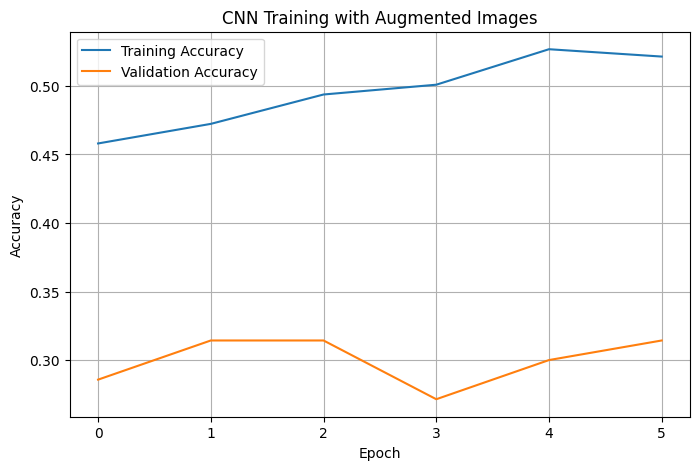

In [61]:
# Train the model using augmented images


from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_aug = model.fit(
    X_train_augmented,
    y_train_augmented,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=16,
    shuffle=True,
    callbacks=[early_stop]
)

val_loss, val_accuracy = model.evaluate(
    X_val,
    y_val
)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)


print("Final Training Accuracy:",
      history_aug.history['accuracy'][-1])

print("Final Validation Accuracy:",
      history_aug.history['val_accuracy'][-1])

plt.figure(figsize=(8, 5))

plt.plot(
    history_aug.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_aug.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Training with Augmented Images')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    history_aug.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_aug.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

## **5. Conclusions** <font color = red> [5 marks]</font>

#### **5.1 Conclude with outcomes and insights gained** <font color =red> [5 marks] </font>

* Report your findings about the data



* Report model training results


#Report your findings about the data

The dataset used for this project contains images of different types of waste materials. The images were classified into seven categories: Cardboard, Food Waste, Glass, Metal, Other, Paper, and Plastic.

To manage the computational requirements and memory limitations, 50 images were selected from each category. Therefore, the final dataset contained 350 images, with an equal number of images in each class.

Waste Category	Number of Images
Cardboard	50
Food Waste	50
Glass	50
Metal	50
Other	50
Paper	50
Plastic	50
Total	350

The dataset is therefore balanced, with each category representing approximately 14.3% of the total dataset. This balanced distribution helps prevent the CNN model from becoming biased toward a particular waste category.

The images were converted to RGB format and resized to 224 × 224 pixels to provide a consistent input size for the CNN model. Pixel values were normalized to the range 0 to 1. The class labels were encoded into seven classes using one-hot encoding.

The dataset was divided into 80% training data and 20% validation data. This resulted in 280 training images and 70 validation images. Stratified splitting was used to maintain the same class distribution in both sets.

Since the original dataset was relatively small, data augmentation was subsequently applied to the training images. Rotation, shifting, zooming, and horizontal flipping were used to generate additional variations of the training images. This increased the effective size of the training dataset and was intended to improve the model's ability to generalize to unseen images.

#Report model training results

Model Training Results

Your original CNN produced these results:

Training accuracy: approximately 61.4% at its best
Validation accuracy: approximately 20%
Validation loss: 7.66 after 50 epochs
Random-guess accuracy for 7 classes: approximately 14.3%

The important observation is that training accuracy increased considerably while validation accuracy remained low. This indicates overfitting.